<a href="https://colab.research.google.com/github/jauniusc/cvmatch/blob/main/notebooks/cvmatch_ai_gemini.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CVMatch AI

This notebook is a prototype of CVMatch AI. The system takes a CV and a job ad and uses the Gemini API to check how well the CV fits the job.

Input `X`: CV text and job ad text.

Output `y`: JSON with these fields:
- `match_score` - number from 0 to 100
- `verdict` - Strong match, Partial match, Weak match or No match
- `matched_skills` - requirements the candidate has
- `missing_skills` - requirements the candidate does not have
- `recommendations` - tips how to improve the CV

To run the notebook, add your Gemini API key to Colab Secrets with the name `GEMINI_API_KEY` and press Runtime -> Run all.

## 1. System overview

The notebook follows the UML diagrams from the README. Every next section is one component:

1. Input Processor - checks and cleans the CV and job ad
2. Prompt Builder - puts the CV and job ad into the prompt template
3. Gemini API - sends the prompt to Gemini and gets JSON back
4. Result Validator - checks the JSON from Gemini
5. REST API `POST /match` - one function that runs all steps

![Component diagram](https://raw.githubusercontent.com/jauniusc/cvmatch/main/diagrams/component.png)

![Sequence diagram](https://raw.githubusercontent.com/jauniusc/cvmatch/main/diagrams/sequence.png)

## 2. Setup

Install the Gemini library and create the client. The API key is taken from Colab Secrets. If there is no key, the notebook still works, but instead of Gemini it uses a simple keyword comparison.

In [1]:
!pip install -q google-genai

In [2]:
import os
import json
import re
import time
import urllib.request

import pandas as pd
import matplotlib.pyplot as plt
from google import genai
from google.genai import types

MODEL = "gemini-flash-lite-latest"

try:
    from google.colab import userdata
    api_key = userdata.get("GEMINI_API_KEY")
except Exception as e:
    print("Could not read GEMINI_API_KEY from Colab Secrets:", type(e).__name__)
    api_key = os.environ.get("GEMINI_API_KEY")

if api_key:
    client = genai.Client(api_key=api_key)
    print("Gemini client is ready, model:", MODEL)
else:
    client = None
    print("No API key found, keyword comparison will be used instead of Gemini")

Gemini client is ready, model: gemini-flash-lite-latest


## 3. Load data

The prompt and the examples are stored in the GitHub repository:
- `prompts/prompt.json` - system prompt and user prompt template
- `data/examples.json` - 4 examples with input `X` and expected output `y`

In [3]:
GITHUB_URL = "https://raw.githubusercontent.com/jauniusc/cvmatch/main/"


def load_json(path):
    if os.path.exists("../" + path):
        with open("../" + path, encoding="utf-8") as f:
            return json.load(f)
    with urllib.request.urlopen(GITHUB_URL + path) as response:
        return json.load(response)


prompt_data = load_json("prompts/prompt.json")
examples = load_json("data/examples.json")

table = pd.DataFrame([
    {"id": ex["id"], "scenario": ex["scenario"], "expected score": ex["y"]["match_score"], "expected verdict": ex["y"]["verdict"]}
    for ex in examples
])
table

,id,scenario,expected score,expected verdict
0,example_01,Strong match: Python developer -> Python backe...,85,Strong match
1,example_02,Partial match: junior Java developer -> full-s...,52,Partial match
2,example_03,No match: accountant -> DevOps engineer role,5,No match
3,example_04,Edge case: very short CV -> junior QA tester role,30,Weak match


In [4]:
print(examples[0]["X"]["cv"])
print()
print(examples[0]["X"]["job_ad"])

Jonas Petrauskas
Backend Developer

EXPERIENCE
2022–present: Python Developer, Data Solutions Ltd, Vilnius. Building REST APIs with Django and Django REST Framework, optimising PostgreSQL queries, deploying services in Docker containers. Set up the CI/CD pipeline with GitLab CI.
2021–2022: Junior Developer, Code Workshop Ltd. Python scripts for data processing, unit tests with pytest.

EDUCATION
Vilnius University, BSc in Computer Science (2021).

SKILLS
Python, Django, DRF, PostgreSQL, Redis, Docker, Git, GitLab CI, pytest, Linux.

LANGUAGES
Lithuanian – native, English – C1.

Python Backend Developer (Vilnius / hybrid)

Requirements:
- 2+ years of commercial experience with Python
- Experience with Django or FastAPI
- Good SQL knowledge (PostgreSQL)
- Experience with Docker
- English at B2 level or higher

Nice to have:
- AWS experience
- Kubernetes knowledge
- Celery or other task queue experience

We offer: 3500–4500 EUR gross, hybrid work.


## 4. Input Processor

This function checks that the CV and the job ad are not empty, removes extra spaces and empty lines, and gives a warning if the CV is very short.

In [5]:
def clean_text(text):
    lines = [line.strip() for line in text.strip().splitlines()]
    text = "\n".join(lines)
    return re.sub(r"\n{3,}", "\n\n", text)


def process_input(cv, job_ad):
    if not cv.strip() or not job_ad.strip():
        raise ValueError("CV and job ad cannot be empty")
    cv = clean_text(cv)
    job_ad = clean_text(job_ad)
    warnings = []
    if len(cv) < 200:
        warnings.append("CV is very short, the result may not be accurate")
    return cv, job_ad, warnings


for ex in examples:
    cv, job_ad, warnings = process_input(ex["X"]["cv"], ex["X"]["job_ad"])
    print(ex["id"], "CV length:", len(cv), "warnings:", warnings)

example_01 CV length: 583 warnings: []
example_02 CV length: 544 warnings: []
example_03 CV length: 443 warnings: []
example_04 CV length: 149 warnings: ['CV is very short, the result may not be accurate']


## 5. Prompt Builder

The system prompt tells Gemini to act as a recruiter and gives the scoring rules. The user prompt template has `{{cv}}` and `{{job_ad}}` places, which are replaced with the real texts.

In [6]:
SYSTEM_PROMPT = prompt_data["system_prompt"]


def build_prompt(cv, job_ad):
    prompt = prompt_data["user_prompt_template"]
    prompt = prompt.replace("{{cv}}", cv)
    prompt = prompt.replace("{{job_ad}}", job_ad)
    return prompt


print(SYSTEM_PROMPT)
print()
print(build_prompt(examples[0]["X"]["cv"], examples[0]["X"]["job_ad"]))

You are an experienced recruiter. Evaluate how well a candidate's CV matches a job advertisement.

Rules:
1. Required qualifications are worth 70% of the score, nice-to-have qualifications 30%.
2. Count a skill as matched only if it is stated in the CV or clearly follows from the described experience.
3. Never invent skills, experience or facts that are not in the CV.
4. If the CV is very short or missing information, lower the score and say so in the recommendations.
5. The verdict depends on the score: 80-100 "Strong match", 50-79 "Partial match", 20-49 "Weak match", 0-19 "No match".
6. Write all text fields in English.

Candidate CV:
"""
Jonas Petrauskas
Backend Developer

EXPERIENCE
2022–present: Python Developer, Data Solutions Ltd, Vilnius. Building REST APIs with Django and Django REST Framework, optimising PostgreSQL queries, deploying services in Docker containers. Set up the CI/CD pipeline with GitLab CI.
2021–2022: Junior Developer, Code Workshop Ltd. Python scripts for data

## 6. Gemini API

The prompt is sent to Gemini with `response_mime_type="application/json"`, so Gemini answers only with JSON. Low temperature (0.2) makes the scores more stable. If the request fails, it is tried again up to 3 times.

In [7]:
def call_gemini(prompt):
    if client is None:
        return None
    config = types.GenerateContentConfig(
        system_instruction=SYSTEM_PROMPT,
        temperature=0.2,
        response_mime_type="application/json",
    )
    for attempt in range(3):
        try:
            response = client.models.generate_content(model=MODEL, contents=prompt, config=config)
            return response.text
        except Exception as e:
            print("Gemini error:", str(e)[:100])
            if "429" in str(e):
                break
            time.sleep(20)
    return None


answer = call_gemini(build_prompt(examples[0]["X"]["cv"], examples[0]["X"]["job_ad"]))
print(answer)

{
  "match_score": 85,
  "verdict": "Strong match",
  "matched_skills": [
    "2+ years of commercial experience with Python",
    "Experience with Django",
    "Good SQL knowledge (PostgreSQL)",
    "Experience with Docker",
    "English at B2 level or higher (C1)"
  ],
  "missing_skills": [
    "AWS experience",
    "Kubernetes knowledge",
    "Celery or other task queue experience"
  ],
  "recommendations": [
    "Highlight any exposure to cloud platforms like AWS if you have worked with them indirectly.",
    "Mention any background knowledge or self-study related to Kubernetes or task queues like Celery if applicable.",
    "Quantify your achievements in your current role, such as performance improvements in PostgreSQL queries or API response times."
  ]
}


If Gemini is not available, a simple keyword comparison is used. It looks for known skills in the job ad and checks if they are also in the CV. It is much less accurate than Gemini, but it gives the same JSON format.

In [8]:
SKILLS = ["Python", "Java", "JavaScript", "TypeScript", "React", "Django", "FastAPI", "Spring Boot",
          "SQL", "REST API", "Docker", "Kubernetes", "Terraform", "AWS", "Azure", "Linux", "Bash",
          "CI/CD", "Celery", "Jira", "Selenium", "Agile", "English"]

VERDICTS = prompt_data["output_format"]["verdicts"]


def get_verdict(score):
    for verdict, (low, high) in VERDICTS.items():
        if low <= score <= high:
            return verdict


def keyword_match(cv, job_ad):
    needed = [s for s in SKILLS if s.lower() in job_ad.lower()]
    matched = [s for s in needed if s.lower() in cv.lower()]
    missing = [s for s in needed if s not in matched]
    score = round(100 * len(matched) / len(needed)) if needed else 0
    return {
        "match_score": score,
        "verdict": get_verdict(score),
        "matched_skills": matched,
        "missing_skills": missing,
        "recommendations": ["Add " + s + " to the CV if you have this skill" for s in missing[:3]],
    }


print(keyword_match(examples[0]["X"]["cv"], examples[0]["X"]["job_ad"]))

{'match_score': 56, 'verdict': 'Partial match', 'matched_skills': ['Python', 'Django', 'SQL', 'Docker', 'English'], 'missing_skills': ['FastAPI', 'Kubernetes', 'AWS', 'Celery'], 'recommendations': ['Add FastAPI to the CV if you have this skill', 'Add Kubernetes to the CV if you have this skill', 'Add AWS to the CV if you have this skill']}


## 7. Result Validator

The answer from Gemini is checked before it is shown to the user:
1. it must be valid JSON
2. it must have all required fields
3. the score must be between 0 and 100
4. the verdict must match the score (for example, 85 must be "Strong match")

In [9]:
REQUIRED_FIELDS = prompt_data["output_format"]["required_fields"]


def validate_result(answer):
    if isinstance(answer, str):
        answer = answer.strip().removeprefix("```json").removesuffix("```")
        answer = json.loads(answer)
    for field in REQUIRED_FIELDS:
        if field not in answer:
            raise ValueError("Missing field: " + field)
    answer["match_score"] = max(0, min(100, int(answer["match_score"])))
    answer["verdict"] = get_verdict(answer["match_score"])
    return answer


test_answer = '{"match_score": 120, "verdict": "Weak match", "matched_skills": [], "missing_skills": [], "recommendations": []}'
print(validate_result(test_answer))

{'match_score': 100, 'verdict': 'Strong match', 'matched_skills': [], 'missing_skills': [], 'recommendations': []}


## 8. REST API POST /match

`post_match` runs all components one after another. A real `POST /match` endpoint would call this function.

In [10]:
def post_match(cv, job_ad):
    cv, job_ad, warnings = process_input(cv, job_ad)
    answer = call_gemini(build_prompt(cv, job_ad))
    source = "gemini"
    try:
        result = validate_result(answer)
    except Exception:
        result = validate_result(keyword_match(cv, job_ad))
        source = "keyword comparison"
    return {"result": result, "source": source, "warnings": warnings}


response = post_match(examples[0]["X"]["cv"], examples[0]["X"]["job_ad"])
print(json.dumps(response, indent=2, ensure_ascii=False))

{
  "result": {
    "match_score": 85,
    "verdict": "Strong match",
    "matched_skills": [
      "2+ years of commercial experience with Python",
      "Experience with Django",
      "Good SQL knowledge (PostgreSQL)",
      "Experience with Docker",
      "English at B2 level or higher (C1)"
    ],
    "missing_skills": [
      "AWS experience",
      "Kubernetes knowledge",
      "Celery or other task queue experience"
    ],
    "recommendations": [
      "Highlight any cloud or infrastructure exposure if you have worked with AWS or Kubernetes in personal projects or past roles.",
      "Mention any asynchronous task processing experience (such as Celery) if applicable.",
      "Quantify the impact of your PostgreSQL query optimizations and API developments in your current role at Data Solutions Ltd."
    ]
  },
  "source": "gemini",
  "warnings": []
}


## 9. Running all examples

Every example from `data/examples.json` is sent to `post_match` and the result is compared with the expected `y`. Two metrics are used:
- MAE - average difference between the expected and the predicted score
- Verdict accuracy - how many verdicts are the same as expected

In [11]:
results = []
for ex in examples:
    response = post_match(ex["X"]["cv"], ex["X"]["job_ad"])
    results.append(response)
    time.sleep(4)

df = pd.DataFrame({
    "id": [ex["id"] for ex in examples],
    "expected score": [ex["y"]["match_score"] for ex in examples],
    "predicted score": [r["result"]["match_score"] for r in results],
    "expected verdict": [ex["y"]["verdict"] for ex in examples],
    "predicted verdict": [r["result"]["verdict"] for r in results],
    "source": [r["source"] for r in results],
})
df["difference"] = abs(df["expected score"] - df["predicted score"])

mae = df["difference"].mean()
accuracy = (df["expected verdict"] == df["predicted verdict"]).mean()
print("MAE:", round(mae, 1))
print("Verdict accuracy:", round(accuracy * 100), "%")
df

Gemini error: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high deman
MAE: 6.8
Verdict accuracy: 50 %


,id,expected score,predicted score,expected verdict,predicted verdict,source,difference
0,example_01,85,85,Strong match,Strong match,gemini,0
1,example_02,52,45,Partial match,Weak match,gemini,7
2,example_03,5,0,No match,No match,gemini,5
3,example_04,30,15,Weak match,No match,gemini,15


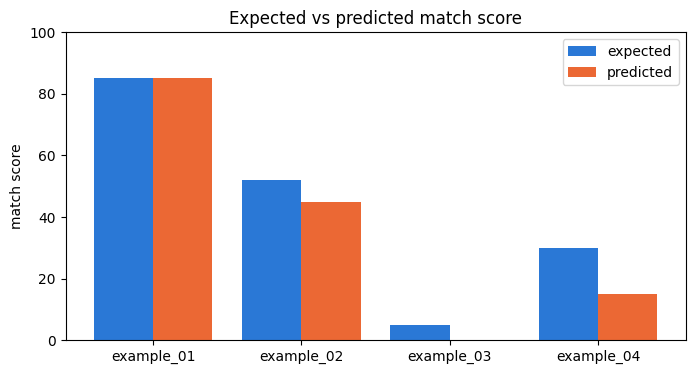

In [12]:
x = range(len(df))
plt.figure(figsize=(8, 4))
plt.bar([i - 0.2 for i in x], df["expected score"], width=0.4, label="expected", color="#2a78d6")
plt.bar([i + 0.2 for i in x], df["predicted score"], width=0.4, label="predicted", color="#eb6834")
plt.xticks(list(x), df["id"])
plt.ylim(0, 100)
plt.ylabel("match score")
plt.title("Expected vs predicted match score")
plt.legend()
plt.show()

In [13]:
def print_report(name, response):
    r = response["result"]
    print(name)
    print("Score:", r["match_score"], "-", r["verdict"], "(" + response["source"] + ")")
    print("Matched:", ", ".join(r["matched_skills"]))
    print("Missing:", ", ".join(r["missing_skills"]))
    print("Recommendations:")
    for tip in r["recommendations"]:
        print(" -", tip)
    if response["warnings"]:
        print("Warnings:", response["warnings"])
    print()


for ex, response in zip(examples, results):
    print_report(ex["id"] + ": " + ex["scenario"], response)

example_01: Strong match: Python developer -> Python backend role
Score: 85 - Strong match (gemini)
Matched: 2+ years of commercial experience with Python, Experience with Django, Good SQL knowledge (PostgreSQL), Experience with Docker, English at B2 level or higher (C1)
Missing: FastAPI, AWS experience, Kubernetes knowledge, Celery or other task queue experience
Recommendations:
 - Highlight any transferable experience or familiarity with task queues like Celery if you have used them in personal or secondary projects.
 - If you have any exposure to cloud platforms like AWS or container orchestration like Kubernetes, even at a basic level, add them to your skills section.
 - Explicitly mention your total years of commercial Python experience in the summary to immediately demonstrate that you meet the 2+ years requirement.

example_02: Partial match: junior Java developer -> full-stack role
Score: 45 - Weak match (gemini)
Matched: Backend: Java (Spring Boot), Knowledge of relational dat

## 10. Test with a new CV

A new example that is not in the data folder. You can paste your own CV and job ad here.

In [14]:
my_cv = """
Laura Mikalauskaitė
Frontend Developer

EXPERIENCE
2022–present: Frontend Developer, Travel Platform Ltd, Vilnius. Building user interfaces with React and TypeScript,
writing component tests with Jest, working with designers in Figma. The team works in Scrum.
2021–2022: Junior Web Developer, Website Studio. HTML, CSS, JavaScript, WordPress themes.

EDUCATION
Vilnius Gediminas Technical University, BSc in Informatics Engineering (2021).

SKILLS
JavaScript, TypeScript, React, Redux, HTML, CSS, REST API, Git, Jest.

LANGUAGES
Lithuanian – native, English – B2.
"""

my_job_ad = """
React Native Developer (Kaunas / remote)

Requirements:
- 2+ years of experience with React or React Native
- Good knowledge of TypeScript
- Experience publishing mobile apps (iOS / Android)
- Working with REST APIs

Nice to have:
- Firebase
- CI/CD for mobile apps
- Agile experience
"""

print_report("My CV", post_match(my_cv, my_job_ad))

My CV
Score: 60 - Partial match (gemini)
Matched: 2+ years of experience with React, Good knowledge of TypeScript, Working with REST APIs, Agile experience
Missing: React Native, Experience publishing mobile apps (iOS / Android), Firebase, CI/CD for mobile apps
Recommendations:
 - Highlight any transferable mobile development experience if you have built mobile-friendly or hybrid apps.
 - Explicitly mention any exposure to mobile app deployment processes or app store publishing if applicable.
 - Add any experience with backend-as-a-service tools like Firebase or similar technologies if used in past projects.
 - Mention familiarity with CI/CD pipelines even if used in web projects to strengthen the nice-to-have qualifications.



## 11. Conclusions

- The prototype works from start to end: it takes a CV and a job ad and returns a checked JSON result.
- Gemini understands the context better than simple keyword search, for example it understands that PostgreSQL means SQL knowledge, and it writes useful recommendations.
- The validator makes sure that the score is between 0 and 100 and that the verdict matches the score.
- 4 examples are not enough for a reliable evaluation, and the expected scores were set by hand, so they are a bit subjective.
- A CV has personal data, so a real system would need to follow GDPR, and the final decision should be made by a person.